- KNN Classifier

In [1]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.datasets import load_breast_cancer

In [ ]:
# load the breast cancer dataset
data=load_breast_cancer()


# create a dataframe from the dataset

df=pd.DataFrame(data.data,columns=data.feature_names)
df['target']=data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.shape

(569, 31)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [5]:
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

Text(0, 0.5, 'Count')

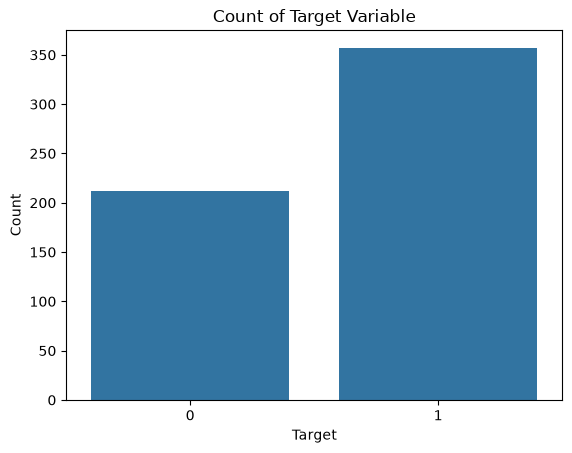

In [7]:
# EDA


sns.countplot(x='target',data=df)

plt.title('Count of Target Variable')
plt.xlabel('Target')
plt.ylabel('Count')

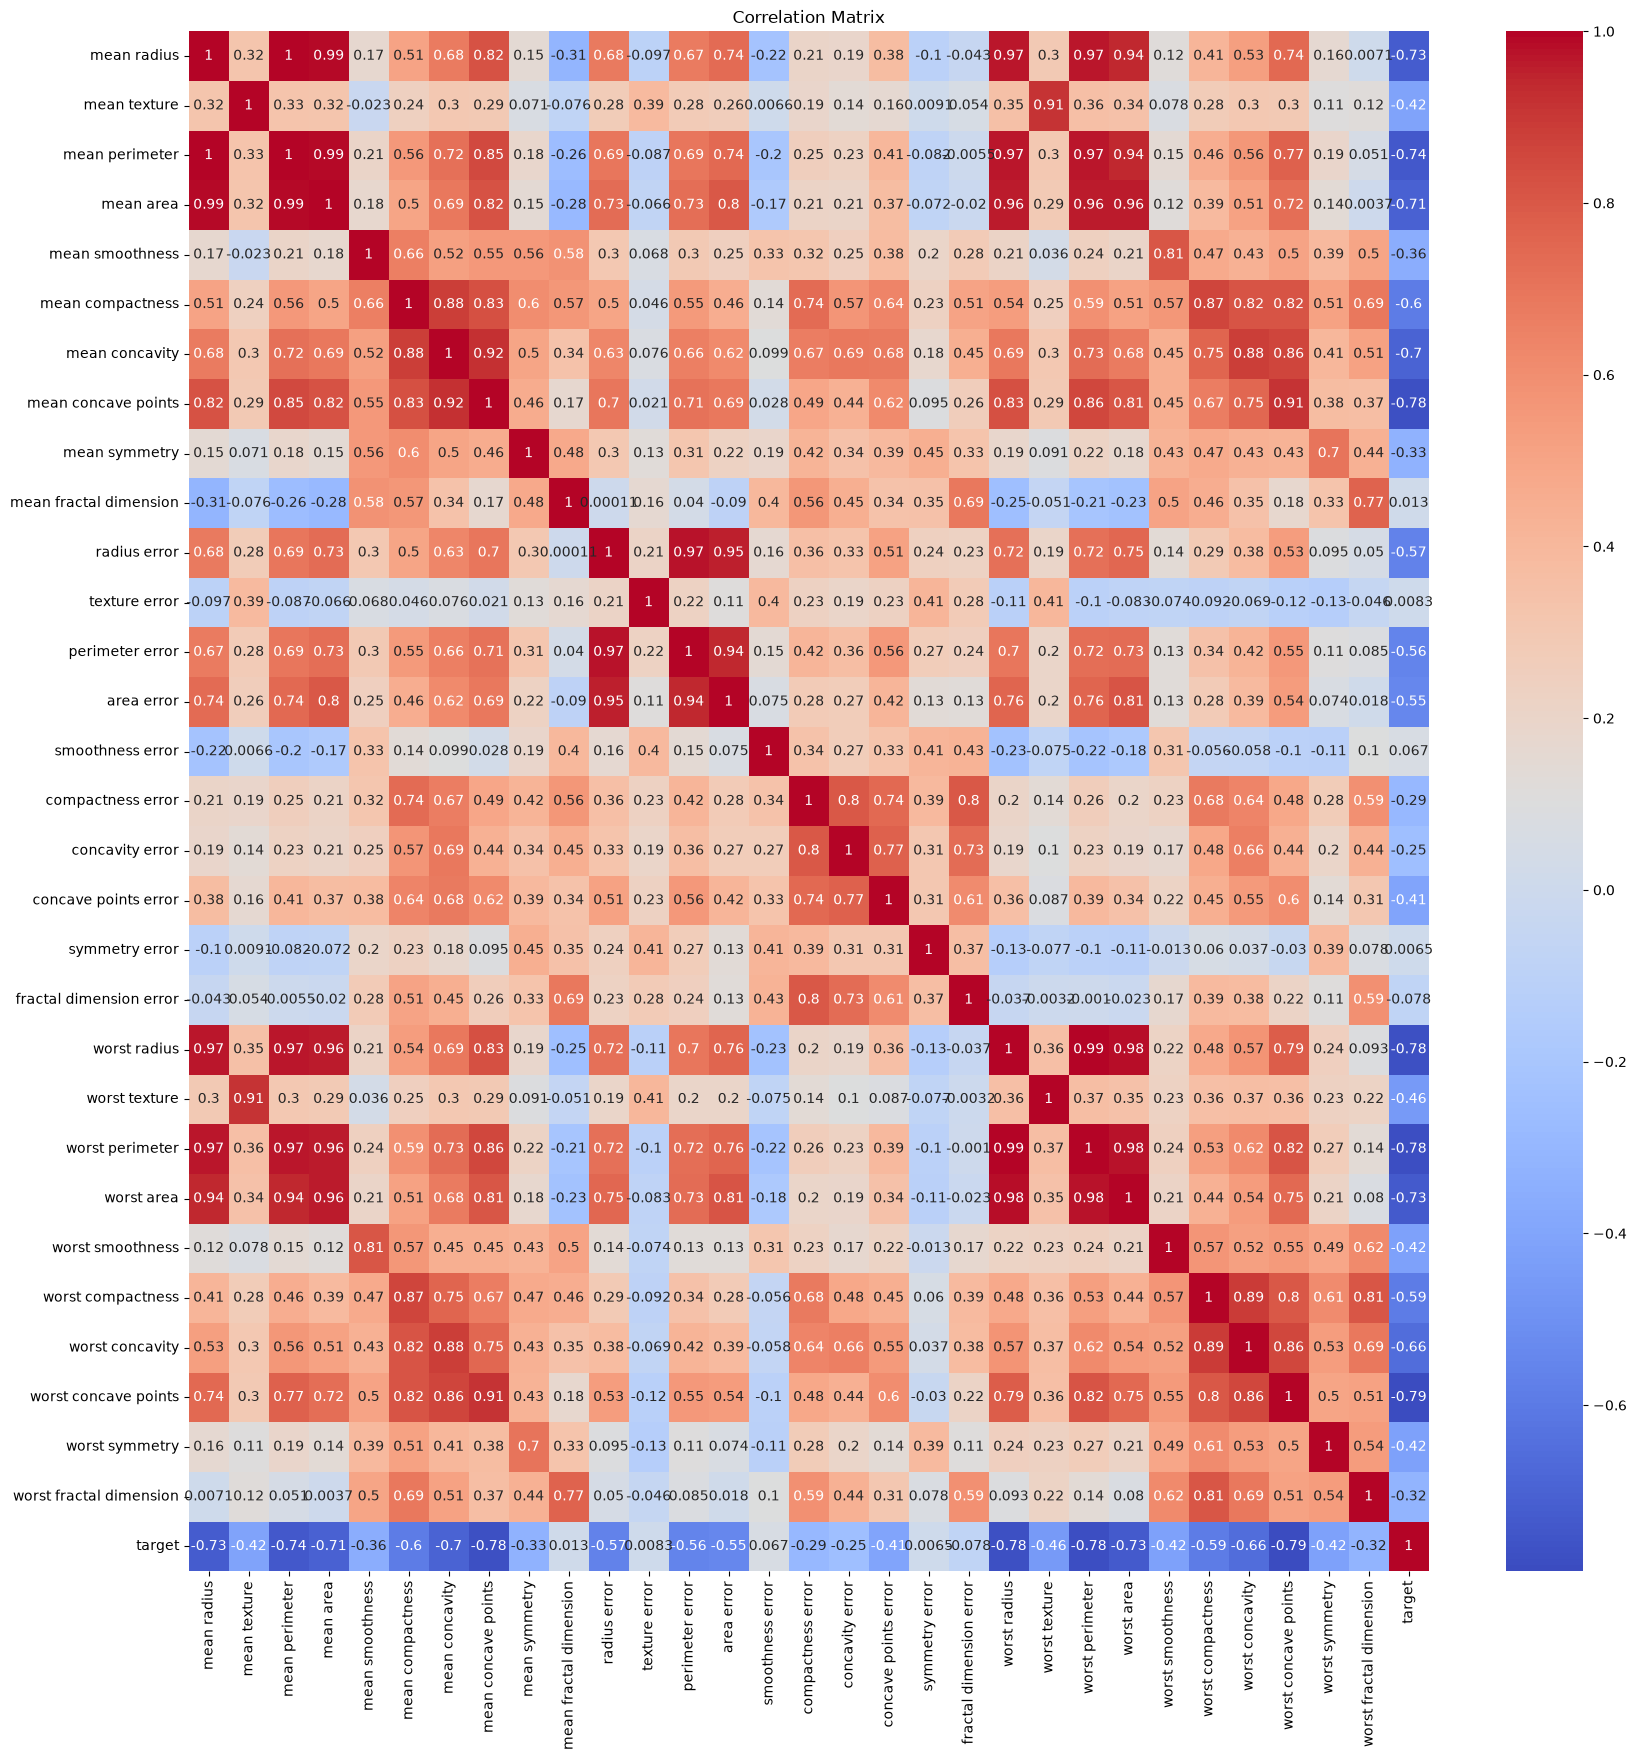

In [8]:
plt.figure(figsize=(20,20))

sns.heatmap(df.corr(),annot=True,cmap='coolwarm')

plt.title('Correlation Matrix')

plt.show()

In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

In [13]:
df.head(1)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.07871,1.095,0.9053,8.589,153.4,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,0


In [14]:
plot_numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [15]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target']])

,variables,VIF
0,mean radius,3806.115296
1,mean texture,11.884048
2,mean perimeter,3786.400419
3,mean area,347.878657
4,mean smoothness,8.194282
5,mean compactness,50.505168
6,mean concavity,70.767720
7,mean concave points,60.041733
8,mean symmetry,4.220656
9,mean fractal dimension,15.756977


In [16]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius']])

,variables,VIF
0,mean texture,11.882933
1,mean perimeter,541.712931
2,mean area,317.093211
3,mean smoothness,7.990641
4,mean compactness,38.106611
5,mean concavity,65.978202
6,mean concave points,60.025840
7,mean symmetry,4.203501
8,mean fractal dimension,15.677673
9,radius error,75.101495


In [17]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius"]])

,variables,VIF
0,mean texture,11.759131
1,mean perimeter,325.641312
2,mean area,237.012095
3,mean smoothness,7.988003
4,mean compactness,36.681620
5,mean concavity,64.836935
6,mean concave points,60.019062
7,mean symmetry,4.123603
8,mean fractal dimension,15.670406
9,radius error,38.637579


In [18]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter"]])

,variables,VIF
0,mean texture,11.714252
1,mean area,34.491349
2,mean smoothness,7.964156
3,mean compactness,31.979571
4,mean concavity,64.655174
5,mean concave points,59.967015
6,mean symmetry,4.123603
7,mean fractal dimension,14.921612
8,radius error,36.056151
9,texture error,4.092556


In [19]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter"]])

,variables,VIF
0,mean texture,11.679833
1,mean area,28.534200
2,mean smoothness,7.909212
3,mean compactness,28.746302
4,mean concavity,64.654796
5,mean concave points,59.816820
6,mean symmetry,4.071436
7,mean fractal dimension,12.724264
8,radius error,36.045576
9,texture error,4.040107


In [20]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity"]])

,variables,VIF
0,mean texture,11.679763
1,mean area,28.512892
2,mean smoothness,7.543056
3,mean compactness,26.110203
4,mean concave points,28.499831
5,mean symmetry,4.064239
6,mean fractal dimension,12.668596
7,radius error,35.617518
8,texture error,4.034866
9,perimeter error,31.178650


In [21]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error"]])

,variables,VIF
0,mean texture,11.465264
1,mean area,25.427695
2,mean smoothness,7.482881
3,mean compactness,26.043226
4,mean concave points,27.801240
5,mean symmetry,4.047744
6,mean fractal dimension,12.232750
7,texture error,4.011486
8,perimeter error,16.007813
9,area error,16.951023


In [22]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness"]])

,variables,VIF
0,mean texture,11.448852
1,mean area,25.389376
2,mean smoothness,7.479515
3,mean compactness,19.208231
4,mean concave points,25.697888
5,mean symmetry,3.982308
6,mean fractal dimension,10.961595
7,texture error,3.998307
8,perimeter error,15.960835
9,area error,16.935889


In [23]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points"]])

,variables,VIF
0,mean texture,11.278555
1,mean area,25.387830
2,mean smoothness,7.162886
3,mean compactness,19.175385
4,mean concave points,19.091402
5,mean symmetry,3.918815
6,mean fractal dimension,10.902634
7,texture error,3.937299
8,perimeter error,15.808730
9,area error,16.917891


In [24]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area"]])

,variables,VIF
0,mean texture,11.179202
1,mean smoothness,7.162712
2,mean compactness,18.843208
3,mean concave points,15.619381
4,mean symmetry,3.895936
5,mean fractal dimension,9.707446
6,texture error,3.937174
7,perimeter error,15.619268
8,area error,16.655447
9,smoothness error,3.632008


In [25]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness"]])

,variables,VIF
0,mean texture,11.134313
1,mean smoothness,6.970849
2,mean concave points,11.753066
3,mean symmetry,3.829642
4,mean fractal dimension,7.907186
5,texture error,3.890957
6,perimeter error,15.333308
7,area error,16.345495
8,smoothness error,3.552541
9,compactness error,6.363339


In [26]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness" and i!="worst texture"]])

,variables,VIF
0,mean texture,1.715846
1,mean smoothness,6.795612
2,mean concave points,11.715292
3,mean symmetry,3.654734
4,mean fractal dimension,7.890069
5,texture error,2.033874
6,perimeter error,15.281161
7,area error,16.333806
8,smoothness error,3.384881
9,compactness error,6.337432


In [27]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness" and i!="worst texture" and i!="area error"]])

,variables,VIF
0,mean texture,1.709993
1,mean smoothness,6.701262
2,mean concave points,11.653729
3,mean symmetry,3.651771
4,mean fractal dimension,7.750052
5,texture error,2.009042
6,perimeter error,4.317808
7,smoothness error,3.338723
8,compactness error,6.317986
9,concavity error,8.849322


In [28]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness" and i!="worst texture" and i!="area error" and i!="worst concavity"]])

,variables,VIF
0,mean texture,1.700532
1,mean smoothness,6.621582
2,mean concave points,8.984360
3,mean symmetry,3.651681
4,mean fractal dimension,7.168068
5,texture error,2.008790
6,perimeter error,4.310524
7,smoothness error,3.235873
8,compactness error,5.889510
9,concavity error,3.966669


In [29]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness" and i!="worst texture" and i!="area error" and i!="worst concavity" and i!="mean concave points"]])

,variables,VIF
0,mean texture,1.696063
1,mean smoothness,5.785490
2,mean symmetry,3.596806
3,mean fractal dimension,7.167990
4,texture error,2.008723
5,perimeter error,4.301484
6,smoothness error,3.224204
7,compactness error,5.749258
8,concavity error,3.965773
9,concave points error,3.996318


In [30]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness" and i!="worst texture" and i!="area error" and i!="worst concavity" and i!="mean concave points" and i!="worst fractal dimension"]])

,variables,VIF
0,mean texture,1.668377
1,mean smoothness,5.596005
2,mean symmetry,3.478491
3,mean fractal dimension,4.770667
4,texture error,2.008040
5,perimeter error,4.298252
6,smoothness error,3.019368
7,compactness error,5.146998
8,concavity error,3.898487
9,concave points error,3.949775


In [31]:
calc_vif(df[[i for i in plot_numeric_features if i != 'target' and i != 'mean radius' and i!="worst radius" and i!="mean perimeter" and i!="worst perimeter" and i!="mean concavity" and i!="radius error" and i!="worst compactness" and i!="worst concave points" and i!="mean area" and i!="mean compactness" and i!="worst texture" and i!="area error" and i!="worst concavity" and i!="mean concave points" and i!="worst fractal dimension" and i!="worst smoothness"]])

,variables,VIF
0,mean texture,1.645067
1,mean smoothness,2.797392
2,mean symmetry,3.032230
3,mean fractal dimension,4.599478
4,texture error,2.007920
5,perimeter error,4.290087
6,smoothness error,1.881640
7,compactness error,5.134582
8,concavity error,3.886040
9,concave points error,3.944298


In [32]:
df.drop(columns=['mean radius' , 'worst radius' , 'mean perimeter' , 'worst perimeter' , 'mean concavity' , 'radius error' , 'worst compactness' , 'worst concave points' , 'mean area' , 'mean compactness' , 'worst texture' , 'area error' , 'worst concavity' , 'mean concave points' , 'worst fractal dimension' , 'worst smoothness'],inplace=True)

In [33]:
df.columns

Index(['mean texture', 'mean smoothness', 'mean symmetry',
       'mean fractal dimension', 'texture error', 'perimeter error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst area', 'worst symmetry', 'target'],
      dtype='str')

In [34]:
# separate the features and target variable

X = df.drop('target', axis=1)
y = df['target']


print(X.shape)
print(y.shape)

(569, 14)
(569,)


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
# feature scaling

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [37]:
# building knn classifier

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [38]:
# making predictions

y_pred = knn.predict(X_test)

print(y_pred)

print(y_test.values)

[1 0 0 1 1 0 0 0 0 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 0 1 0
 1 1 1 1 1 1 0 1 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 1 0]
[1 0 0 1 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 0 1 1 0 1 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 1 0]


In [40]:
# model evaluation

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

In [41]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred)) 

Accuracy: 0.9385964912280702
Precision: 0.9324324324324325
Recall: 0.971830985915493
F1 Score: 0.9517241379310345
Confusion Matrix:
[[38  5]
 [ 2 69]]
